<a href="https://colab.research.google.com/github/Sanhith30/ITA0605-ML/blob/main/Lab%20Exercises/Exp18_Perceptron_Iris.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 18: Perceptron-based Iris Classification
**Course:** ITA06 - Machine Learning (Lab)

## Aim
Implement Perceptron-based IRIS classification.

## Background
The **Perceptron** (Rosenblatt, 1958) is the simplest neural network: `y_hat = 1 if w.x + b >= 0 else 0`. On each mistake it updates `w <- w + lr * (y - y_hat) * x` and `b <- b + lr * (y - y_hat)`. The **Perceptron convergence theorem** guarantees zero training errors in finitely many updates *if the classes are linearly separable*; otherwise the weights keep oscillating. For 3 classes we use **One-vs-Rest** (one perceptron per class).



## Setup: Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
np.random.seed(42)
print("Libraries imported successfully")

Libraries imported successfully


## Step 1: Data Collection
Load Iris from scikit-learn and save it as a CSV.

In [2]:
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)
frame = iris.frame.copy()
frame["species"] = frame["target"].map(dict(enumerate(iris.target_names)))
frame = frame.drop(columns="target")
frame.columns = ["sepal_length", "sepal_width", "petal_length", "petal_width", "species"]
frame.to_csv("iris.csv", index=False)
print("Saved iris.csv", frame.shape)

Saved iris.csv (150, 5)


## Step 2: Data Loading

In [3]:
df = pd.read_csv("iris.csv")
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## Step 3: Data Preprocessing
Encode labels, split (stratified) and standardise the features (perceptrons converge much faster on scaled inputs).

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

print("Missing:", df.isnull().sum().sum())
features = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
le = LabelEncoder()
y = le.fit_transform(df["species"])
X = df[features].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
scaler = StandardScaler().fit(X_train)
X_train_s, X_test_s = scaler.transform(X_train), scaler.transform(X_test)
print("Classes:", dict(enumerate(le.classes_)), "| Train:", X_train_s.shape, "Test:", X_test_s.shape)

Missing: 0
Classes: {0: 'setosa', 1: 'versicolor', 2: 'virginica'} | Train: (120, 4) Test: (30, 4)


## Step 4: Exploratory Data Analysis (EDA)
The key question for a perceptron: **which classes are linearly separable?**

              count  mean   std  min  25%   50%  75%  max
sepal_length  150.0  5.84  0.83  4.3  5.1  5.80  6.4  7.9
sepal_width   150.0  3.06  0.44  2.0  2.8  3.00  3.3  4.4
petal_length  150.0  3.76  1.77  1.0  1.6  4.35  5.1  6.9
petal_width   150.0  1.20  0.76  0.1  0.3  1.30  1.8  2.5


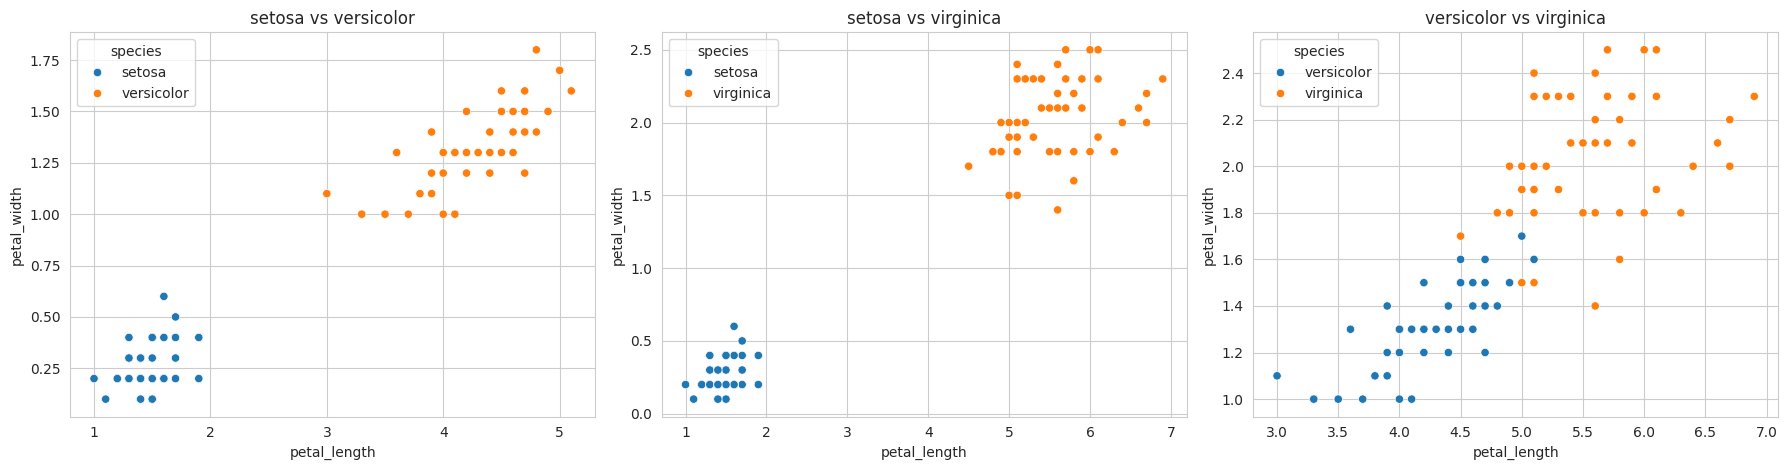

Setosa is clearly separable from the others; versicolor and virginica overlap slightly.


In [5]:
print(df.describe().T.round(2))
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
pairs = [("setosa", "versicolor"), ("setosa", "virginica"), ("versicolor", "virginica")]
for ax, (a, b) in zip(axes, pairs):
    sub = df[df["species"].isin([a, b])]
    sns.scatterplot(data=sub, x="petal_length", y="petal_width", hue="species", ax=ax)
    ax.set_title(f"{a} vs {b}")
plt.tight_layout(); plt.show()
print("Setosa is clearly separable from the others; versicolor and virginica overlap slightly.")

## Step 5: Model Training (Perceptron from scratch)
Implement the perceptron learning rule, train it on a separable pair (setosa vs versicolor) and on a non-separable pair (versicolor vs virginica), and track the **number of mistakes per epoch**.

Setosa vs versicolor -> converged in 2 epochs; training accuracy = 1.0
Versicolor vs virginica -> epochs run: 50 | final-epoch mistakes: 5 | training accuracy = 0.938


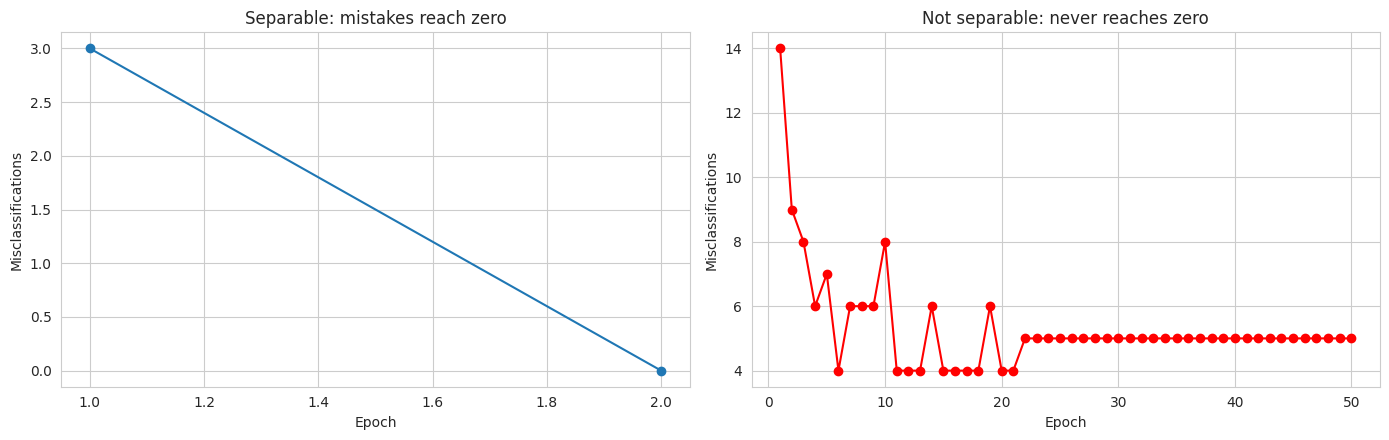

In [6]:
class Perceptron:
    def __init__(self, lr=0.1, epochs=50):
        self.lr, self.epochs = lr, epochs

    def net_input(self, X):
        return X @ self.w + self.b

    def predict(self, X):
        return np.where(self.net_input(X) >= 0, 1, 0)

    def fit(self, X, y):
        self.w, self.b = np.zeros(X.shape[1]), 0.0
        self.errors_per_epoch = []
        for _ in range(self.epochs):
            errors = 0
            for xi, yi in zip(X, y):
                update = self.lr * (yi - self.predict(xi.reshape(1, -1))[0])
                self.w += update * xi
                self.b += update
                errors += int(update != 0.0)
            self.errors_per_epoch.append(errors)
            if errors == 0:                      # converged
                break
        return self

# (a) Separable: setosa (0) vs versicolor (1) using the petal features
mask = np.isin(y_train, [0, 1])
Xa, ya = X_train_s[mask][:, 2:4], y_train[mask]
p_sep = Perceptron(lr=0.1, epochs=50).fit(Xa, ya)
print("Setosa vs versicolor -> converged in", len(p_sep.errors_per_epoch), "epochs; training accuracy =", (p_sep.predict(Xa) == ya).mean())

# (b) Not separable: versicolor (0) vs virginica (1)
mask2 = np.isin(y_train, [1, 2])
Xb, yb = X_train_s[mask2][:, 2:4], (y_train[mask2] == 2).astype(int)
p_non = Perceptron(lr=0.1, epochs=50).fit(Xb, yb)
print("Versicolor vs virginica -> epochs run:", len(p_non.errors_per_epoch), "| final-epoch mistakes:", p_non.errors_per_epoch[-1],
      "| training accuracy =", round((p_non.predict(Xb) == yb).mean(), 3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(range(1, len(p_sep.errors_per_epoch) + 1), p_sep.errors_per_epoch, marker="o"); axes[0].set_title("Separable: mistakes reach zero")
axes[1].plot(range(1, len(p_non.errors_per_epoch) + 1), p_non.errors_per_epoch, marker="o", color="red"); axes[1].set_title("Not separable: never reaches zero")
for ax in axes: ax.set_xlabel("Epoch"); ax.set_ylabel("Misclassifications")
plt.tight_layout(); plt.show()

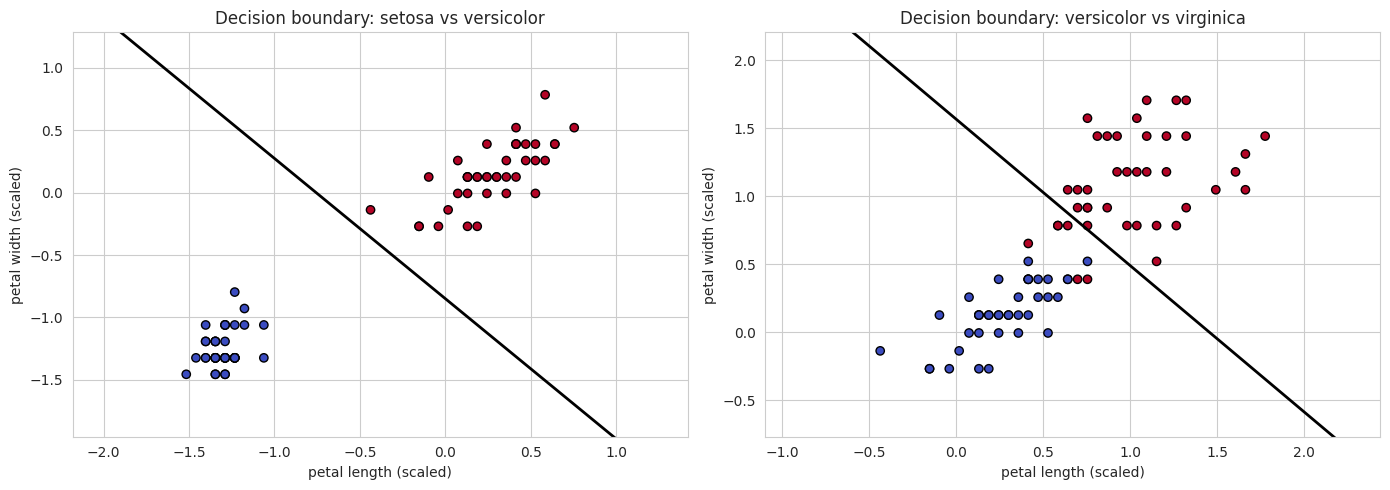

In [7]:
# Decision boundaries learned by the two perceptrons
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (Xp, yp, model, title) in zip(axes, [(Xa, ya, p_sep, "setosa vs versicolor"), (Xb, yb, p_non, "versicolor vs virginica")]):
    ax.scatter(Xp[:, 0], Xp[:, 1], c=yp, cmap="coolwarm", edgecolor="k")
    xs = np.linspace(Xp[:, 0].min() - .5, Xp[:, 0].max() + .5, 100)
    ax.plot(xs, -(model.w[0] * xs + model.b) / model.w[1], "k-", linewidth=2)
    ax.set_ylim(Xp[:, 1].min() - .5, Xp[:, 1].max() + .5)
    ax.set_xlabel("petal length (scaled)"); ax.set_ylabel("petal width (scaled)"); ax.set_title(f"Decision boundary: {title}")
plt.tight_layout(); plt.show()

In [8]:
# Multi-class: One-vs-Rest with 3 perceptrons on all four features
class OneVsRestPerceptron:
    def __init__(self, lr=0.1, epochs=100):
        self.lr, self.epochs = lr, epochs
    def fit(self, X, y):
        self.classes = np.unique(y)
        self.models = [Perceptron(self.lr, self.epochs).fit(X, (y == c).astype(int)) for c in self.classes]
        return self
    def predict(self, X):
        scores = np.column_stack([m.net_input(X) for m in self.models])
        return self.classes[np.argmax(scores, axis=1)]

ovr = OneVsRestPerceptron(lr=0.1, epochs=100).fit(X_train_s, y_train)
print("Scratch One-vs-Rest perceptron trained. Mistakes in the last epoch per class:",
      [m.errors_per_epoch[-1] for m in ovr.models])

Scratch One-vs-Rest perceptron trained. Mistakes in the last epoch per class: [0, 44, 6]


## Step 6: Model Evaluation
Evaluate the multi-class perceptron on the test set, compare with scikit-learn's `Perceptron`, and use cross-validation.

Scratch OvR perceptron - test accuracy: 0.9333
scikit-learn Perceptron - test accuracy: 0.8667
sklearn 5-fold CV accuracy: [0.5   0.967 0.7   0.9   0.733] | mean = 0.76
              precision    recall  f1-score   support

      setosa       0.91      1.00      0.95        10
  versicolor       0.90      0.90      0.90        10
   virginica       1.00      0.90      0.95        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



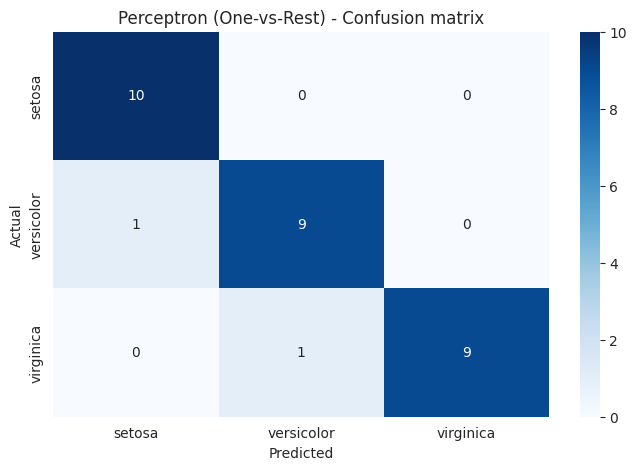

In [9]:
from sklearn.linear_model import Perceptron as SkPerceptron
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline

y_pred = ovr.predict(X_test_s)
print("Scratch OvR perceptron - test accuracy:", round(accuracy_score(y_test, y_pred), 4))

sk = SkPerceptron(max_iter=1000, eta0=0.1, random_state=42).fit(X_train_s, y_train)
print("scikit-learn Perceptron - test accuracy:", round(sk.score(X_test_s, y_test), 4))
cv = cross_val_score(make_pipeline(StandardScaler(), SkPerceptron(max_iter=1000, random_state=42)), X, y, cv=5)
print("sklearn 5-fold CV accuracy:", cv.round(3), "| mean =", round(cv.mean(), 3))

print(classification_report(y_test, y_pred, target_names=le.classes_))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues", xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Perceptron (One-vs-Rest) - Confusion matrix"); plt.show()

In [10]:
# Classic limitation: a single perceptron can learn AND but not XOR
Xl = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], float)
for name, yl in [("AND", np.array([0, 0, 0, 1])), ("XOR", np.array([0, 1, 1, 0]))]:
    pl = Perceptron(lr=0.1, epochs=100).fit(Xl, yl)
    print(f"{name}: accuracy = {(pl.predict(Xl) == yl).mean():.2f}   (mistakes in the final epoch: {pl.errors_per_epoch[-1]})")

AND: accuracy = 1.00   (mistakes in the final epoch: 0)
XOR: accuracy = 0.50   (mistakes in the final epoch: 4)


## Step 7: Prediction on New Data

In [11]:
new_flowers = np.array([[5.0, 3.4, 1.5, 0.2], [5.9, 2.8, 4.3, 1.3], [6.8, 3.0, 5.6, 2.1]])
pred = ovr.predict(scaler.transform(new_flowers))
for row, p in zip(new_flowers, pred):
    print(row, "->", le.classes_[p])

[5.  3.4 1.5 0.2] -> setosa
[5.9 2.8 4.3 1.3] -> versicolor
[6.8 3.  5.6 2.1] -> virginica


## Conclusion
The perceptron separated *setosa* from the other species perfectly, reaching zero mistakes within a couple of epochs, but it never reaches zero on *versicolor vs virginica* because those classes are not linearly separable - the mistakes keep fluctuating. The One-vs-Rest perceptron therefore handles setosa flawlessly and makes its errors on the other two classes (the versicolor-vs-rest unit can never converge). Its accuracy (roughly 85-93% on the test split) is below K-NN or Naive Bayes and varies a lot between splits - 5-fold CV of scikit-learn's Perceptron ranged from about 0.5 to 0.97 - because the algorithm never settles on non-separable data. The AND/XOR demo shows the historic limitation that led to multi-layer networks (Experiment 4).